# Decision-Aware Knowledge Base: Offline Build and Evaluation on EDC

- This notebook runs the whole offline half on 10 decision records of
  `eclipse-edc/Connector`, then checks each stage against the draft answer
  keys in `specs/gold/` and tries the tuning knobs that need no API key
- The pedagogical arc:
  - Build the knowledge base: records, links, graph, staleness, gaps
  - How well are records read?
  - How well are records linked to code, and which signal helps?
  - Which records look stale, and how the threshold changes that
  - Which complex modules have no decision record
- The answer keys were written by one person and are not reviewed yet, so
  read the numbers as a first check, not a finding

In [1]:
!pip install -q --root-user-action=ignore lizard==1.25.0 markdown-it-py==4.0.0 networkx==3.5 python-dotenv==1.2.4

import lizard
import markdown_it
import networkx

print("lizard version: ", lizard.version)
print("markdown-it-py version: ", markdown_it.__version__)
print("networkx version: ", networkx.__version__)

lizard version:  1.25.0
markdown-it-py version:  4.0.0
networkx version:  3.5


In [2]:
%load_ext autoreload
%autoreload 2

import logging

import pandas as pd

In [3]:
import helpers.hnotebook as hnotebook

import UmdTask745_MSML610_Fall2026_AI_Knowledge_Management_Development_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Make the `adrqa` package under `src/` importable.
utils.add_src_to_path()

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp_6ahc1rh.json --HistoryManager.hist_file=:memory:


In [4]:
import adrqa.config as aconfig
import adrqa.gitstore as agitsto
import adrqa.offline as aofflin

# Part 1: Build the Knowledge Base

## Cell 1.1: Run the Offline Build

- Same as `python -m adrqa build`: clone once, parse, link, build the graph,
  score staleness, rank gaps, and write JSON to `data/`
- Without an API key the replacement finder is the rule-based parser only
- Scoring staleness follows each file's history, so this takes a little
  while

In [5]:
result = aofflin.build_offline(log=_LOG.info)
print(
    f"records: {len(result['records'])}, links: {len(result['links'])}, "
    f"gap modules: {len(result['gaps'])}"
)

parsing records
no chat model configured: using rule-based replacement detection only
linking records to code


scoring staleness (follows renames per file, this takes a few minutes)


ranking documentation gaps


records: 10, links: 128, gap modules: 20


## Cell 1.2: What Was Written

- Each stage leaves one JSON file, so later stages and the second half of
  the project read files instead of rerunning anything

In [6]:
for path in sorted((aconfig.DATA_DIR).glob("*.json")):
    print(f"{path.name:28s} {path.stat().st_size / 1024:8.1f} KB")

adr_commit_signal.json            1.8 KB
gap_report.json                   2.3 KB
graph.json                       52.6 KB
links.json                       36.7 KB
records.json                     39.2 KB
staleness.json                    2.1 KB


# Part 2: Reading the Records

## Cell 2.1: The Parsed Records

In [7]:
records = utils.load_json("records.json")
display(utils.records_table(records))

,record,title,date,fields_found,references,supersedes
0,2025-05-28-dataspace-profile-context,Dataspace Profile Context,2025-05-28,3,0,
1,2025-07-25-multiple-participant-identifiers,Different participant identifiers for Dataspac...,2025-07-25,3,1,
2,2025-08-26-participant-context,Participant Context (EDC Virtual),2025-08-26,3,1,
3,2025-10-15-participant-context-config,Participant Context Configuration,2025-10-15,3,0,
4,2025-10-29-participant-identifiers,Participants Identifiers resolution,2025-10-29,3,1,
5,2026-05-11-multi-profile-virtual-connector,Multi-Profile Support in EDC Virtual,2026-05-11,3,3,
6,2026-09-22-per-participant-resource-ids,Per-participant resource identifiers,2026-09-22,3,1,2025-08-26-participant-context (partial)
7,2026-09-24-remove-atomikos,Remove the Atomikos transaction extension,2026-09-24,3,0,
8,2025-02-07-http-proxy-data-plane-deprecation,Deprecation of HTTP Proxy in the Data Plane,2025-02-07,3,0,
9,2024-10-10-daps-deprecation,DAPS module deprecation,2024-10-10,3,0,


## Cell 2.2: Score Against the Extraction Key

In [8]:
display(utils.extraction_scores(records, utils.load_gold("extraction.json")))

,field,correct,total
0,title,10,10
1,date,10,10
2,decision,10,10
3,rationale,10,10
4,approach,10,10
5,references,7,7
6,supersedes,1,1


- Everything is read correctly, but all 10 records follow one template, so
  this says little about messier repositories
- EDC records have no status line, so status is never scored

# Part 3: Linking Records to Code

## Cell 3.1: Precision and Recall of the Links

- A directory in the linking key stands for its non-test code files

In [9]:
links = utils.load_json("links.json")
gold_pairs = utils.expand_gold(
    utils.load_gold("linking.json"), agitsto.GitStore().tree
)
display(pd.DataFrame([utils.link_scores(links, gold_pairs)]))

,predicted,correct,gold,precision,recall
0,128,72,75,0.56,0.96


- Nearly every right file is found (recall), but only about half of the
  links are right (precision)
- Wrong links come from names mentioned in passing and sentences like "this
  will remain unchanged"

## Cell 3.2: Switch Each Signal Off

- Which signal earns its place? Drop one at a time and score the rest

In [10]:
display(utils.signal_ablation(links, gold_pairs))

,setting,predicted,correct,gold,precision,recall
0,all signals,128,72,75,0.56,0.96
1,without explicit_class,55,22,75,0.40,0.29
2,without explicit_module,87,64,75,0.74,0.85
3,without explicit_path,115,59,75,0.51,0.79
4,without explicit_file,127,71,75,0.56,0.95
5,without adr_commit,128,72,75,0.56,0.96


- `explicit_class` carries the recall: without it recall collapses
- `explicit_module` adds most of the wrong links: dropping it raises
  precision but loses some right files, a trade-off worth tuning
- `adr_commit` adds nothing on EDC

## Cell 3.3: Why the Commit Signal Is Empty

In [11]:
display(pd.DataFrame(utils.load_json("adr_commit_signal.json")))

,record_id,commit,files,code_files,code_files_still_present
0,2025-05-28-dataspace-profile-context,8ad147b8fd7912f181f4457fc8f8fd50b9a1bf7a,2,0,0
1,2025-07-25-multiple-participant-identifiers,6438222e0fa68bae43a3d95a38b4493b6b0f58f6,2,0,0
2,2025-08-26-participant-context,09b24974f621ac95cb238ecaf15b00fdfa19af80,2,0,0
3,2025-10-15-participant-context-config,0ef62ebe11a7869cf36ab862f651e0ead3dc35ee,2,0,0
4,2025-10-29-participant-identifiers,84eeb92203cb851b5c557418f53da41d2eb3ba45,2,0,0
5,2026-05-11-multi-profile-virtual-connector,1370959c690535b59212204d6bd03793ed59257c,2,0,0
6,2026-09-22-per-participant-resource-ids,bb07ccc67a2342c756d3680c8eadbac8971d4644,2,0,0
7,2026-09-24-remove-atomikos,de28060a4714d9995912b74190e4e2ee63052e84,2,0,0
8,2025-02-07-http-proxy-data-plane-deprecation,5761ab73f6a84c0717a90f083145365423989633,2,0,0
9,2024-10-10-daps-deprecation,dda8fa46de899f5440ac3516ed4f9458f9fe0e58,5,3,0


- The commits that added the records touched no code that still exists

# Part 4: Staleness

## Cell 4.1: Scores Per Record

In [12]:
scores = utils.load_json("staleness.json")
threshold = aconfig.get_settings().stale_warn_threshold
display(utils.staleness_table(scores, threshold))

,record_id,churn_code,edits_after_first,n_linked_files,stale,flagged
0,2025-08-26-participant-context,63.0,1,15,31.5,True
1,2025-07-25-multiple-participant-identifiers,27.0,0,16,27.0,True
2,2025-05-28-dataspace-profile-context,16.0,0,3,16.0,True
3,2026-09-22-per-participant-resource-ids,11.0,0,21,11.0,False
4,2025-10-15-participant-context-config,10.0,0,6,10.0,False
5,2025-10-29-participant-identifiers,9.0,0,4,9.0,False
6,2026-05-11-multi-profile-virtual-connector,17.0,1,49,8.5,False
7,2026-09-24-remove-atomikos,0.0,0,14,0.0,False
8,2025-02-07-http-proxy-data-plane-deprecation,NaN,0,0,NaN,False
9,2024-10-10-daps-deprecation,NaN,0,0,NaN,False


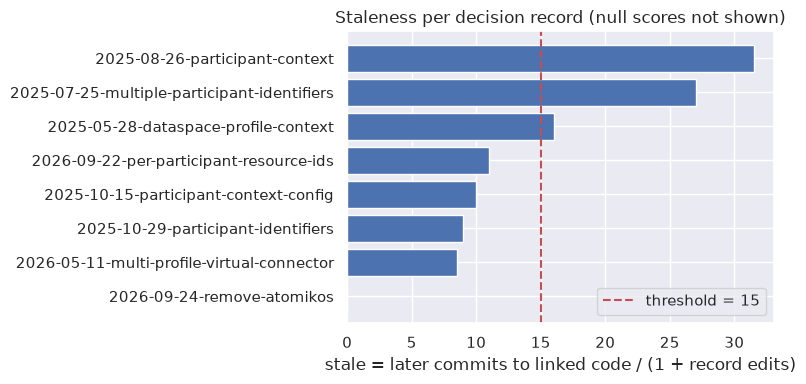

In [13]:
utils.plot_staleness(scores, threshold)

- Two records get no score (null), not 0: no linked code was found, so
  there is nothing to measure
- The count includes the commits that carried the decision out, so a high
  score is a hint to check the record, not proof it is wrong

## Cell 4.2: How the Threshold Changes the Warnings

- The default of 15 is untested, so try a few values

In [14]:
display(utils.threshold_sweep(scores, [5, 10, 15, 25]))

,threshold,flagged,records
0,5,7,"2025-05-28-dataspace-profile-context, 2025-07-..."
1,10,5,"2025-05-28-dataspace-profile-context, 2025-07-..."
2,15,3,"2025-05-28-dataspace-profile-context, 2025-07-..."
3,25,2,"2025-07-25-multiple-participant-identifiers, 2..."


# Part 5: Documentation Gaps

## Cell 5.1: Complex Modules Without a Record

In [15]:
gaps = utils.load_json("gap_report.json")
display(pd.DataFrame(gaps).head(10))

,module,complexity,coverage,gap
0,spi/control-plane-spi,1754,0.091,1594.09
1,core/common/lib/core-lib,1188,0.019,1165.44
2,spi/core-spi,1067,0.059,1004.50
3,core/control-plane/lib/control-plane-lib,366,0.000,366.00
4,core/control-plane/control-plane-transform,310,0.000,310.00
5,core/control-plane/control-plane-aggregate-ser...,308,0.038,296.15
6,data-protocols/dsp/dsp-lib,251,0.000,251.00
7,core/common/boot,248,0.000,248.00
8,data-protocols/data-plane-signaling/data-plane...,215,0.000,215.00
9,extensions/common/vault/vault-hashicorp,209,0.000,209.00


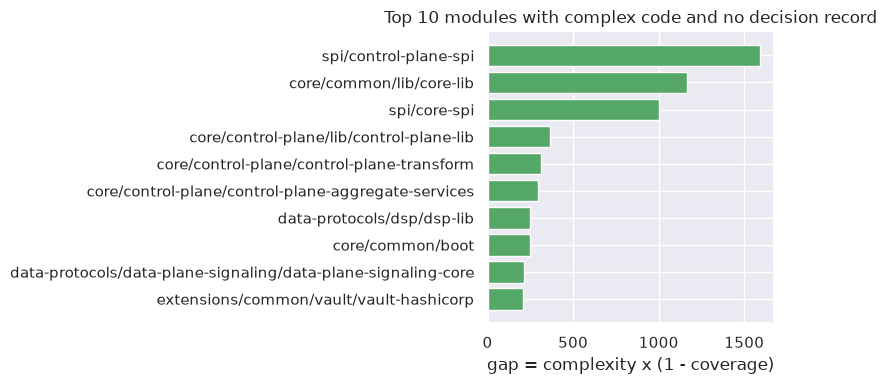

In [16]:
utils.plot_gaps(gaps, top=10)

- Coverage only counts the 10 records used here, out of 113 in the
  repository, so a module shown as uncovered may have a record we skipped

# Takeaways

- The offline half turns loose Markdown records into a graph that answers
  "which decisions govern this code?" and "what replaced this decision?"
  without any model
- Reading records is solved on this corpus; linking is the weak stage, with
  high recall and low precision
- Staleness and gaps are cheap hints that point a reviewer at records and
  modules worth a look
- The second half of the project (next PR) uses this graph to answer
  questions with citations